In [1]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA


file_path = '/home/znb/Downloads/Classification/Dataset.csv'
# Load the dataset
df = pd.read_csv(file_path)
df

/tmp/ipykernel_2258142/3182822188.py:12: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)


,src_ip,dst_ip,src_port,dst_port,protocol,timestamp,flow_duration,flow_byts_s,flow_pkts_s,fwd_pkts_s,...,bwd_blk_rate_avg,fwd_seg_size_avg,bwd_seg_size_avg,cwr_flag_count,subflow_fwd_pkts,subflow_bwd_pkts,subflow_fwd_byts,subflow_bwd_byts,Label,Label1
0,192.168.0.38,192.168.10.224,34026,80,6,2026-06-12,0.000472,7.500000e+05,10593.220339,8474.576271,...,0.0,70.000000,74.000000,0,4,1,280,74,Malicious,Vulnerability-Scan
1,192.168.0.38,192.168.10.224,48348,443,6,2026-06-12,0.000496,5.685484e+05,8064.516129,6048.387097,...,0.0,69.333333,74.000000,0,3,1,208,74,Malicious,Vulnerability-Scan
2,192.168.0.38,192.168.10.224,44684,111,6,2026-06-12,0.000011,1.836364e+07,272727.272727,181818.181818,...,0.0,74.000000,54.000000,0,2,1,148,54,Malicious,Vulnerability-Scan
3,192.168.0.38,192.168.10.224,55330,993,6,2026-06-12,0.000003,6.733333e+07,1000000.000000,666666.666667,...,0.0,74.000000,54.000000,0,2,1,148,54,Malicious,Vulnerability-Scan
4,192.168.0.38,192.168.10.224,37904,113,6,2026-06-12,0.000004,5.050000e+07,750000.000000,500000.000000,...,0.0,74.000000,54.000000,0,2,1,148,54,Malicious,Vulnerability-Scan
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
376000,192.168.0.38,192.168.10.224,50550,21,6,2026-06-18,37.409257,1.466749e+02,1.951389,0.989060,...,0.0,70.783784,79.666667,0,37,36,2619,2868,Malicious,FTP-BruteForce
376001,192.168.0.38,192.168.10.224,50566,21,6,2026-06-18,52.994919,1.544865e+02,2.056801,1.037835,...,0.0,70.636364,79.666667,0,55,54,3885,4302,Malicious,FTP-BruteForce
376002,192.168.0.38,192.168.10.224,50492,21,6,2026-06-18,52.992986,1.345461e+02,1.830431,0.981262,...,0.0,68.961538,78.755556,0,52,45,3586,3544,Malicious,FTP-BruteForce
376003,192.168.0.38,192.168.10.224,50572,21,6,2026-06-18,52.995054,1.375411e+02,1.830359,0.924615,...,0.0,70.714286,79.666667,0,49,48,3465,3824,Malicious,FTP-BruteForce


In [2]:
# Drop rows by finding the index locations where label1 is 'port'
df = df.drop(df[df['Label1'] == 'Port'].index)

In [3]:
df["Label1"].value_counts()


Label1
SSH-BruteForce        67600
FTP-BruteForce        57685
Vulnerability-Scan    52068
Network-Scan          51673
FTP-Enumeration       51467
Host-Discovery        43663
Name: count, dtype: int64

In [4]:
file_path1 = '/home/znb/Downloads/Classification/BBenign.csv'

# Load the dataset
df1 = pd.read_csv(file_path1)
df1

,src_ip,dst_ip,src_port,dst_port,protocol,timestamp,flow_duration,flow_byts_s,flow_pkts_s,fwd_pkts_s,...,fwd_blk_rate_avg,bwd_blk_rate_avg,fwd_seg_size_avg,bwd_seg_size_avg,cwr_flag_count,subflow_fwd_pkts,subflow_bwd_pkts,subflow_fwd_byts,subflow_bwd_byts,Label1
0,192.168.0.38,192.168.10.224,22,34818,6,2026-09-23,0.397790,2.928030e+07,18314.380705,14320.776440,...,5.846555e+07,0.000000,2007.170764,66.785812,0,5759,1606,12160914,108068,Benign
1,192.168.10.20,192.168.0.70,50844,41514,6,2026-09-23,0.060336,3.113233e+05,861.840361,298.329356,...,-6.204301e+01,-0.960204,930.222222,60.000000,0,18,34,16744,2040,Benign
2,172.67.167.23,192.168.10.85,443,61817,6,2026-09-23,0.866328,2.289087e+04,109.658236,72.720725,...,3.505686e+04,0.000000,284.301587,60.000000,0,63,32,17911,1920,Benign
3,139.84.134.56,192.168.10.31,443,64130,6,2026-09-23,0.931094,1.173029e+04,84.846428,38.664195,...,-1.356396e+01,-5.774318,200.888889,85.813953,0,36,43,7232,3690,Benign
4,192.168.0.38,192.168.10.96,22,52417,6,2026-09-23,0.000836,1.327751e+06,8373.205742,5980.861244,...,0.000000e+00,0.000000,198.000000,60.000000,0,5,2,990,120,Benign
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
53720,192.168.10.240,172.67.155.181,21909,443,6,2026-09-23,0.010985,5.289030e+05,1092.398726,637.232590,...,0.000000e+00,0.000000,203.857143,876.600000,0,7,5,1427,4383,Benign
53721,192.168.10.241,192.168.0.65,50232,39092,6,2026-09-23,0.000538,1.189591e+06,9293.680297,5576.208178,...,0.000000e+00,0.000000,144.666667,103.000000,0,3,2,434,206,Benign
53722,108.139.60.57,192.168.10.91,443,57951,6,2026-09-23,0.061240,6.956238e+03,97.975180,65.316786,...,0.000000e+00,0.000000,76.500000,60.000000,0,4,2,306,120,Benign
53723,92.38.180.105,192.168.10.47,443,43976,6,2026-09-23,0.000168,1.178571e+06,17857.142857,11904.761905,...,0.000000e+00,0.000000,66.000000,66.000000,0,2,1,132,66,Benign


In [5]:
mer_df = pd.concat([df, df1], ignore_index=True)

In [6]:
mer_df["Label1"].value_counts()
mer_df = mer_df.drop(['Label'], axis=1)   # X is all columns except the label

In [7]:
mer_df = mer_df.drop(['src_ip','dst_ip','src_port','dst_port','protocol','timestamp'], axis=1)   # X is all columns except the label

In [8]:
merged_df=mer_df

In [9]:
print(merged_df.shape)

(377881, 77)


In [10]:
merged_df = merged_df.sample(frac=1, random_state=42).reset_index(drop=True)
print(merged_df.head())

   flow_duration    flow_byts_s  flow_pkts_s  fwd_pkts_s  bwd_pkts_s  \
0       0.000000       0.000000     0.000000    0.000000    0.000000   
1       4.121580    1291.980260     6.065635    3.154130    2.911505   
2       3.183144  104818.694976    76.339619   47.123222   29.216397   
3       0.261189   54684.538782   134.002581   72.744258   61.258323   
4       0.000000       0.000000     0.000000    0.000000    0.000000   

   tot_fwd_pkts  tot_bwd_pkts  totlen_fwd_pkts  totlen_bwd_pkts  \
0             2             0              148                0   
1            13            12             2859             2466   
2           150            93           299907            33746   
3            19            16             4932             9351   
4             2             0              162                0   

   fwd_pkt_len_max  ...  fwd_blk_rate_avg  bwd_blk_rate_avg  fwd_seg_size_avg  \
0               74  ...      0.000000e+00      0.000000e+00         74.000000   
1 

In [11]:
# Show unique values in the 'Label' column
print(merged_df["Label1"].unique())

['Host-Discovery' 'SSH-BruteForce' 'Benign' 'Vulnerability-Scan'
 'FTP-Enumeration' 'Network-Scan' 'FTP-BruteForce']


In [12]:
from sklearn.preprocessing import LabelEncoder
le_label = LabelEncoder()

# Encode columns
merged_df["Label1"] = le_label.fit_transform(merged_df["Label1"])

In [13]:
# Get unique label classes
label_classes = merged_df['Label1'].unique()
print("Label Classes:", label_classes)

Label Classes: [3 5 0 6 2 4 1]


In [14]:
from sklearn.preprocessing import StandardScaler

# Columns to exclude from scaling
non_numeric_cols = ['Label1']

# Select only numeric columns from merged_df
numeric_cols = merged_df.select_dtypes(include=['int64', 'float64']).columns
cols_to_scale = [col for col in numeric_cols if col not in non_numeric_cols]

# Replace infinite values with NaN
merged_df[cols_to_scale] = merged_df[cols_to_scale].replace([np.inf, -np.inf], np.nan)

# We will fit the scaler later on the selected features.
# For now, just show the head without scaling.
print(merged_df.head())

   flow_duration    flow_byts_s  flow_pkts_s  fwd_pkts_s  bwd_pkts_s  \
0       0.000000       0.000000     0.000000    0.000000    0.000000   
1       4.121580    1291.980260     6.065635    3.154130    2.911505   
2       3.183144  104818.694976    76.339619   47.123222   29.216397   
3       0.261189   54684.538782   134.002581   72.744258   61.258323   
4       0.000000       0.000000     0.000000    0.000000    0.000000   

   tot_fwd_pkts  tot_bwd_pkts  totlen_fwd_pkts  totlen_bwd_pkts  \
0             2             0              148                0   
1            13            12             2859             2466   
2           150            93           299907            33746   
3            19            16             4932             9351   
4             2             0              162                0   

   fwd_pkt_len_max  ...  fwd_blk_rate_avg  bwd_blk_rate_avg  fwd_seg_size_avg  \
0               74  ...      0.000000e+00      0.000000e+00         74.000000   
1 

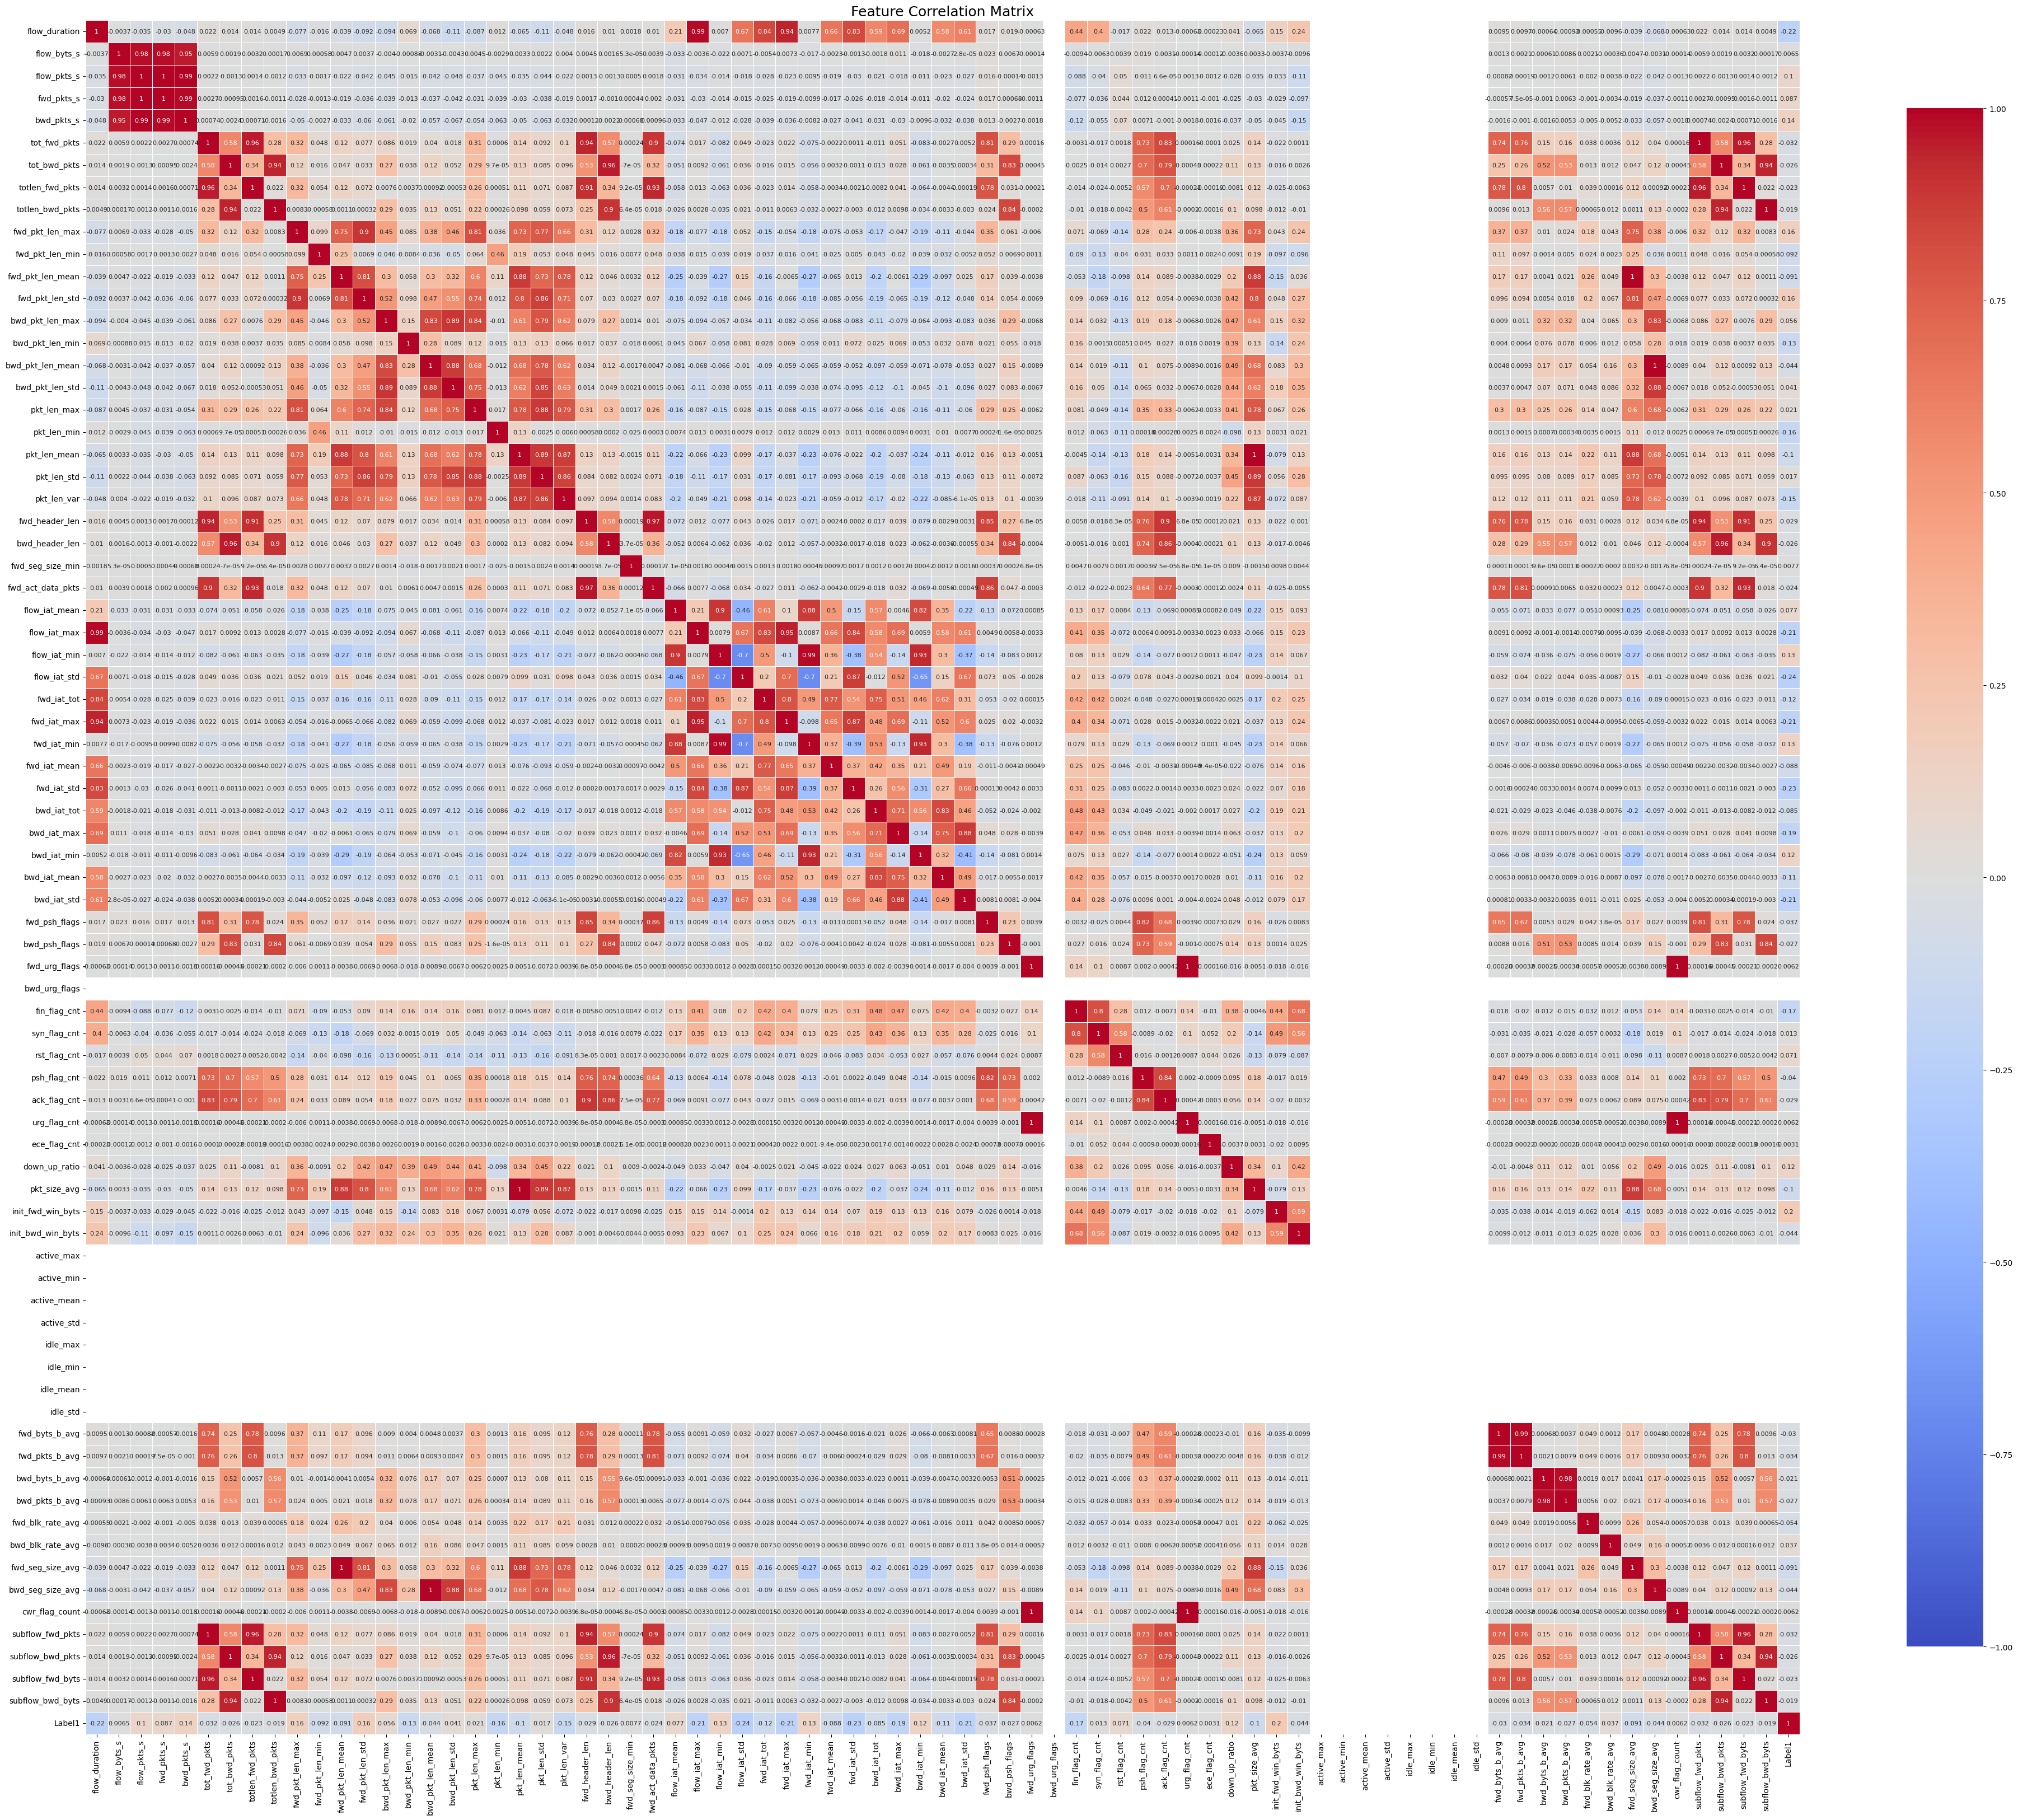

Top 20 highest correlations:
pkt_size_avg    pkt_len_mean      0.999972
pkt_len_mean    pkt_size_avg      0.999972
fwd_pkts_s      flow_pkts_s       0.999395
flow_pkts_s     fwd_pkts_s        0.999395
bwd_pkts_s      flow_pkts_s       0.993904
flow_pkts_s     bwd_pkts_s        0.993904
fwd_byts_b_avg  fwd_pkts_b_avg    0.990988
fwd_pkts_b_avg  fwd_byts_b_avg    0.990988
flow_duration   flow_iat_max      0.990171
flow_iat_max    flow_duration     0.990171
fwd_pkts_s      bwd_pkts_s        0.989470
bwd_pkts_s      fwd_pkts_s        0.989470
fwd_iat_min     flow_iat_min      0.985789
flow_iat_min    fwd_iat_min       0.985789
fwd_pkts_s      flow_byts_s       0.983224
flow_byts_s     fwd_pkts_s        0.983224
bwd_byts_b_avg  bwd_pkts_b_avg    0.982344
bwd_pkts_b_avg  bwd_byts_b_avg    0.982344
flow_byts_s     flow_pkts_s       0.977937
flow_pkts_s     flow_byts_s       0.977937
dtype: float64


In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Select ONLY numeric columns automatically
numeric_df = merged_df.select_dtypes(include=[np.number])

# Calculate correlation matrix
corr_matrix = numeric_df.corr()

# Plot heatmap
plt.figure(figsize=(40, 35))

sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    annot=True,
    annot_kws={'size': 8}
)

plt.title('Feature Correlation Matrix', fontsize=18)

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

# =========================================================
# HIGH CORRELATIONS
# =========================================================

high_corr = corr_matrix.abs().unstack()

# Remove duplicate/self correlations
high_corr = high_corr[
    high_corr < 1
].sort_values(ascending=False)

print("Top 20 highest correlations:")
print(high_corr.head(20))

In [16]:


import numpy as np
import pandas as pd

# Select only numeric feature columns (exclude target column)
numeric_features = (
    merged_df
    .drop(columns=["Label1"], errors="ignore")
    .select_dtypes(include=np.number)
)

# Compute absolute correlation matrix
corr_matrix = numeric_features.corr().abs()

# Extract upper triangle
upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# Find highly correlated features
to_drop = [
    column for column in upper.columns
    if any(upper[column] > 0.80)
]

print("Number of features to drop:", len(to_drop))
print("\nFeatures to drop:")
print(to_drop)

# Drop correlated features from original dataframe
merged_df_reduced = merged_df.drop(columns=to_drop)

print("\nOriginal shape:", merged_df.shape)
print("Reduced shape:", merged_df_reduced.shape)

# Verify Label still exists
print("\nIs 'Label' present in reduced dataset?",
      "Label" in merged_df_reduced.columns)

Number of features to drop: 40

Features to drop:
['flow_pkts_s', 'fwd_pkts_s', 'bwd_pkts_s', 'totlen_fwd_pkts', 'totlen_bwd_pkts', 'fwd_pkt_len_std', 'bwd_pkt_len_mean', 'bwd_pkt_len_std', 'pkt_len_max', 'pkt_len_mean', 'pkt_len_std', 'pkt_len_var', 'fwd_header_len', 'bwd_header_len', 'fwd_act_data_pkts', 'flow_iat_max', 'flow_iat_min', 'fwd_iat_tot', 'fwd_iat_max', 'fwd_iat_min', 'fwd_iat_std', 'bwd_iat_min', 'bwd_iat_mean', 'bwd_iat_std', 'fwd_psh_flags', 'bwd_psh_flags', 'syn_flag_cnt', 'psh_flag_cnt', 'ack_flag_cnt', 'urg_flag_cnt', 'pkt_size_avg', 'fwd_pkts_b_avg', 'bwd_pkts_b_avg', 'fwd_seg_size_avg', 'bwd_seg_size_avg', 'cwr_flag_count', 'subflow_fwd_pkts', 'subflow_bwd_pkts', 'subflow_fwd_byts', 'subflow_bwd_byts']

Original shape: (377881, 77)
Reduced shape: (377881, 37)

Is 'Label' present in reduced dataset? False


In [17]:
merged_df=merged_df_reduced

Saved: Feature_Correlation_Matrix.png


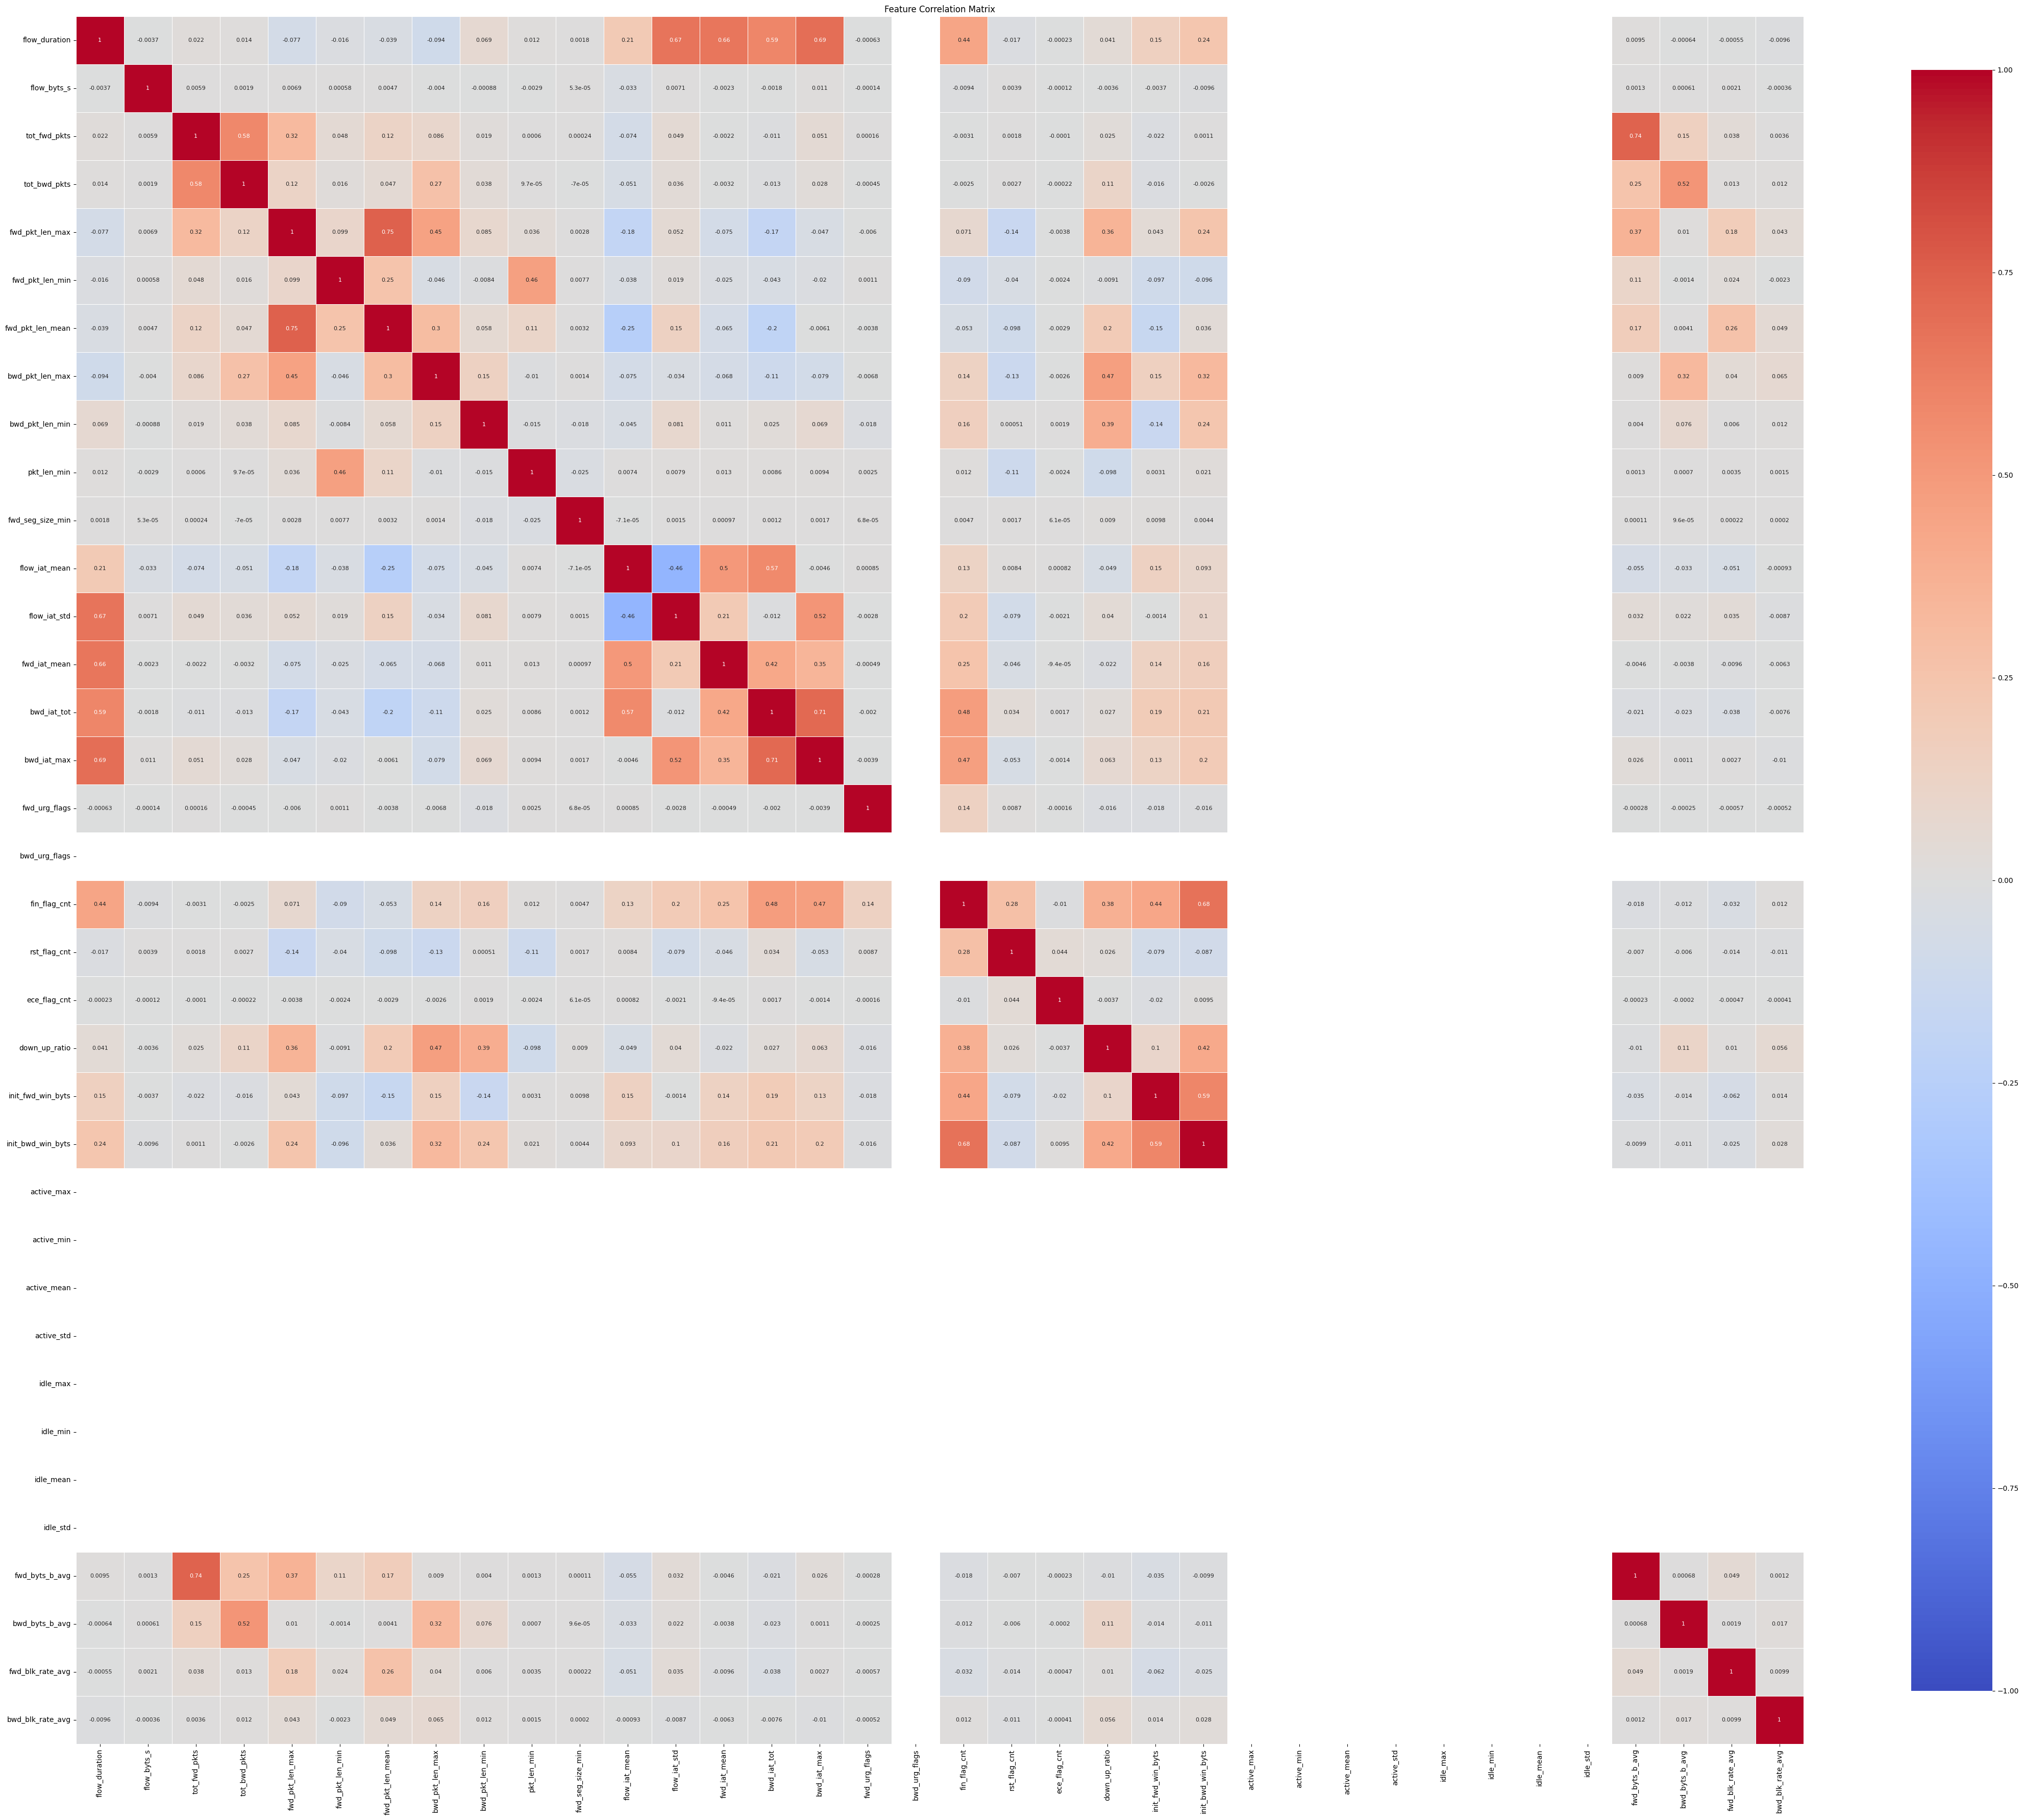

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

numeric_df = merged_df.select_dtypes(include=[np.number])

# Drop Label column
numeric_df = numeric_df.drop(columns=["Label1"], errors="ignore")

# Correlation matrix
corr_matrix = numeric_df.corr()

# Create figure
plt.figure(figsize=(44, 40))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    annot=True,
    annot_kws={"size": 8}
)

plt.title("Feature Correlation Matrix")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()

# Save BEFORE showing
plt.savefig(
    "Feature_Correlation_Matrix.png",
    dpi=500,
    bbox_inches="tight"
)

print("Saved: Feature_Correlation_Matrix.png")

plt.show()

In [19]:

# Keep only numeric columns from merged_df
numeric_df = merged_df.select_dtypes(include=[np.number])

# Compute correlation matrix on numeric data
correlation_matrix = numeric_df.corr()

# Choose correlation column: 'Label' or 'Label_encoded'
target_column = 'Label1'  # or 'Label_encoded' if using encoded labels

# Get correlation of all features with the label column
label_corr = correlation_matrix[target_column]

# Set threshold
threshold = 0.01

# Keep only features with abs(correlation) > threshold
features_to_keep = label_corr[abs(label_corr) > threshold].index.tolist()

# Ensure the target column is included
if target_column not in features_to_keep:
    features_to_keep.append(target_column)

# Filter original merged_df using the selected numeric features
merged_df = merged_df[features_to_keep]

# Print results
print("Kept features:", features_to_keep)
print("Filtered shape:", merged_df.shape)


Kept features: ['flow_duration', 'tot_fwd_pkts', 'tot_bwd_pkts', 'fwd_pkt_len_max', 'fwd_pkt_len_min', 'fwd_pkt_len_mean', 'bwd_pkt_len_max', 'bwd_pkt_len_min', 'pkt_len_min', 'flow_iat_mean', 'flow_iat_std', 'fwd_iat_mean', 'bwd_iat_tot', 'bwd_iat_max', 'fin_flag_cnt', 'rst_flag_cnt', 'down_up_ratio', 'init_fwd_win_byts', 'init_bwd_win_byts', 'fwd_byts_b_avg', 'bwd_byts_b_avg', 'fwd_blk_rate_avg', 'bwd_blk_rate_avg', 'Label1']
Filtered shape: (377881, 24)


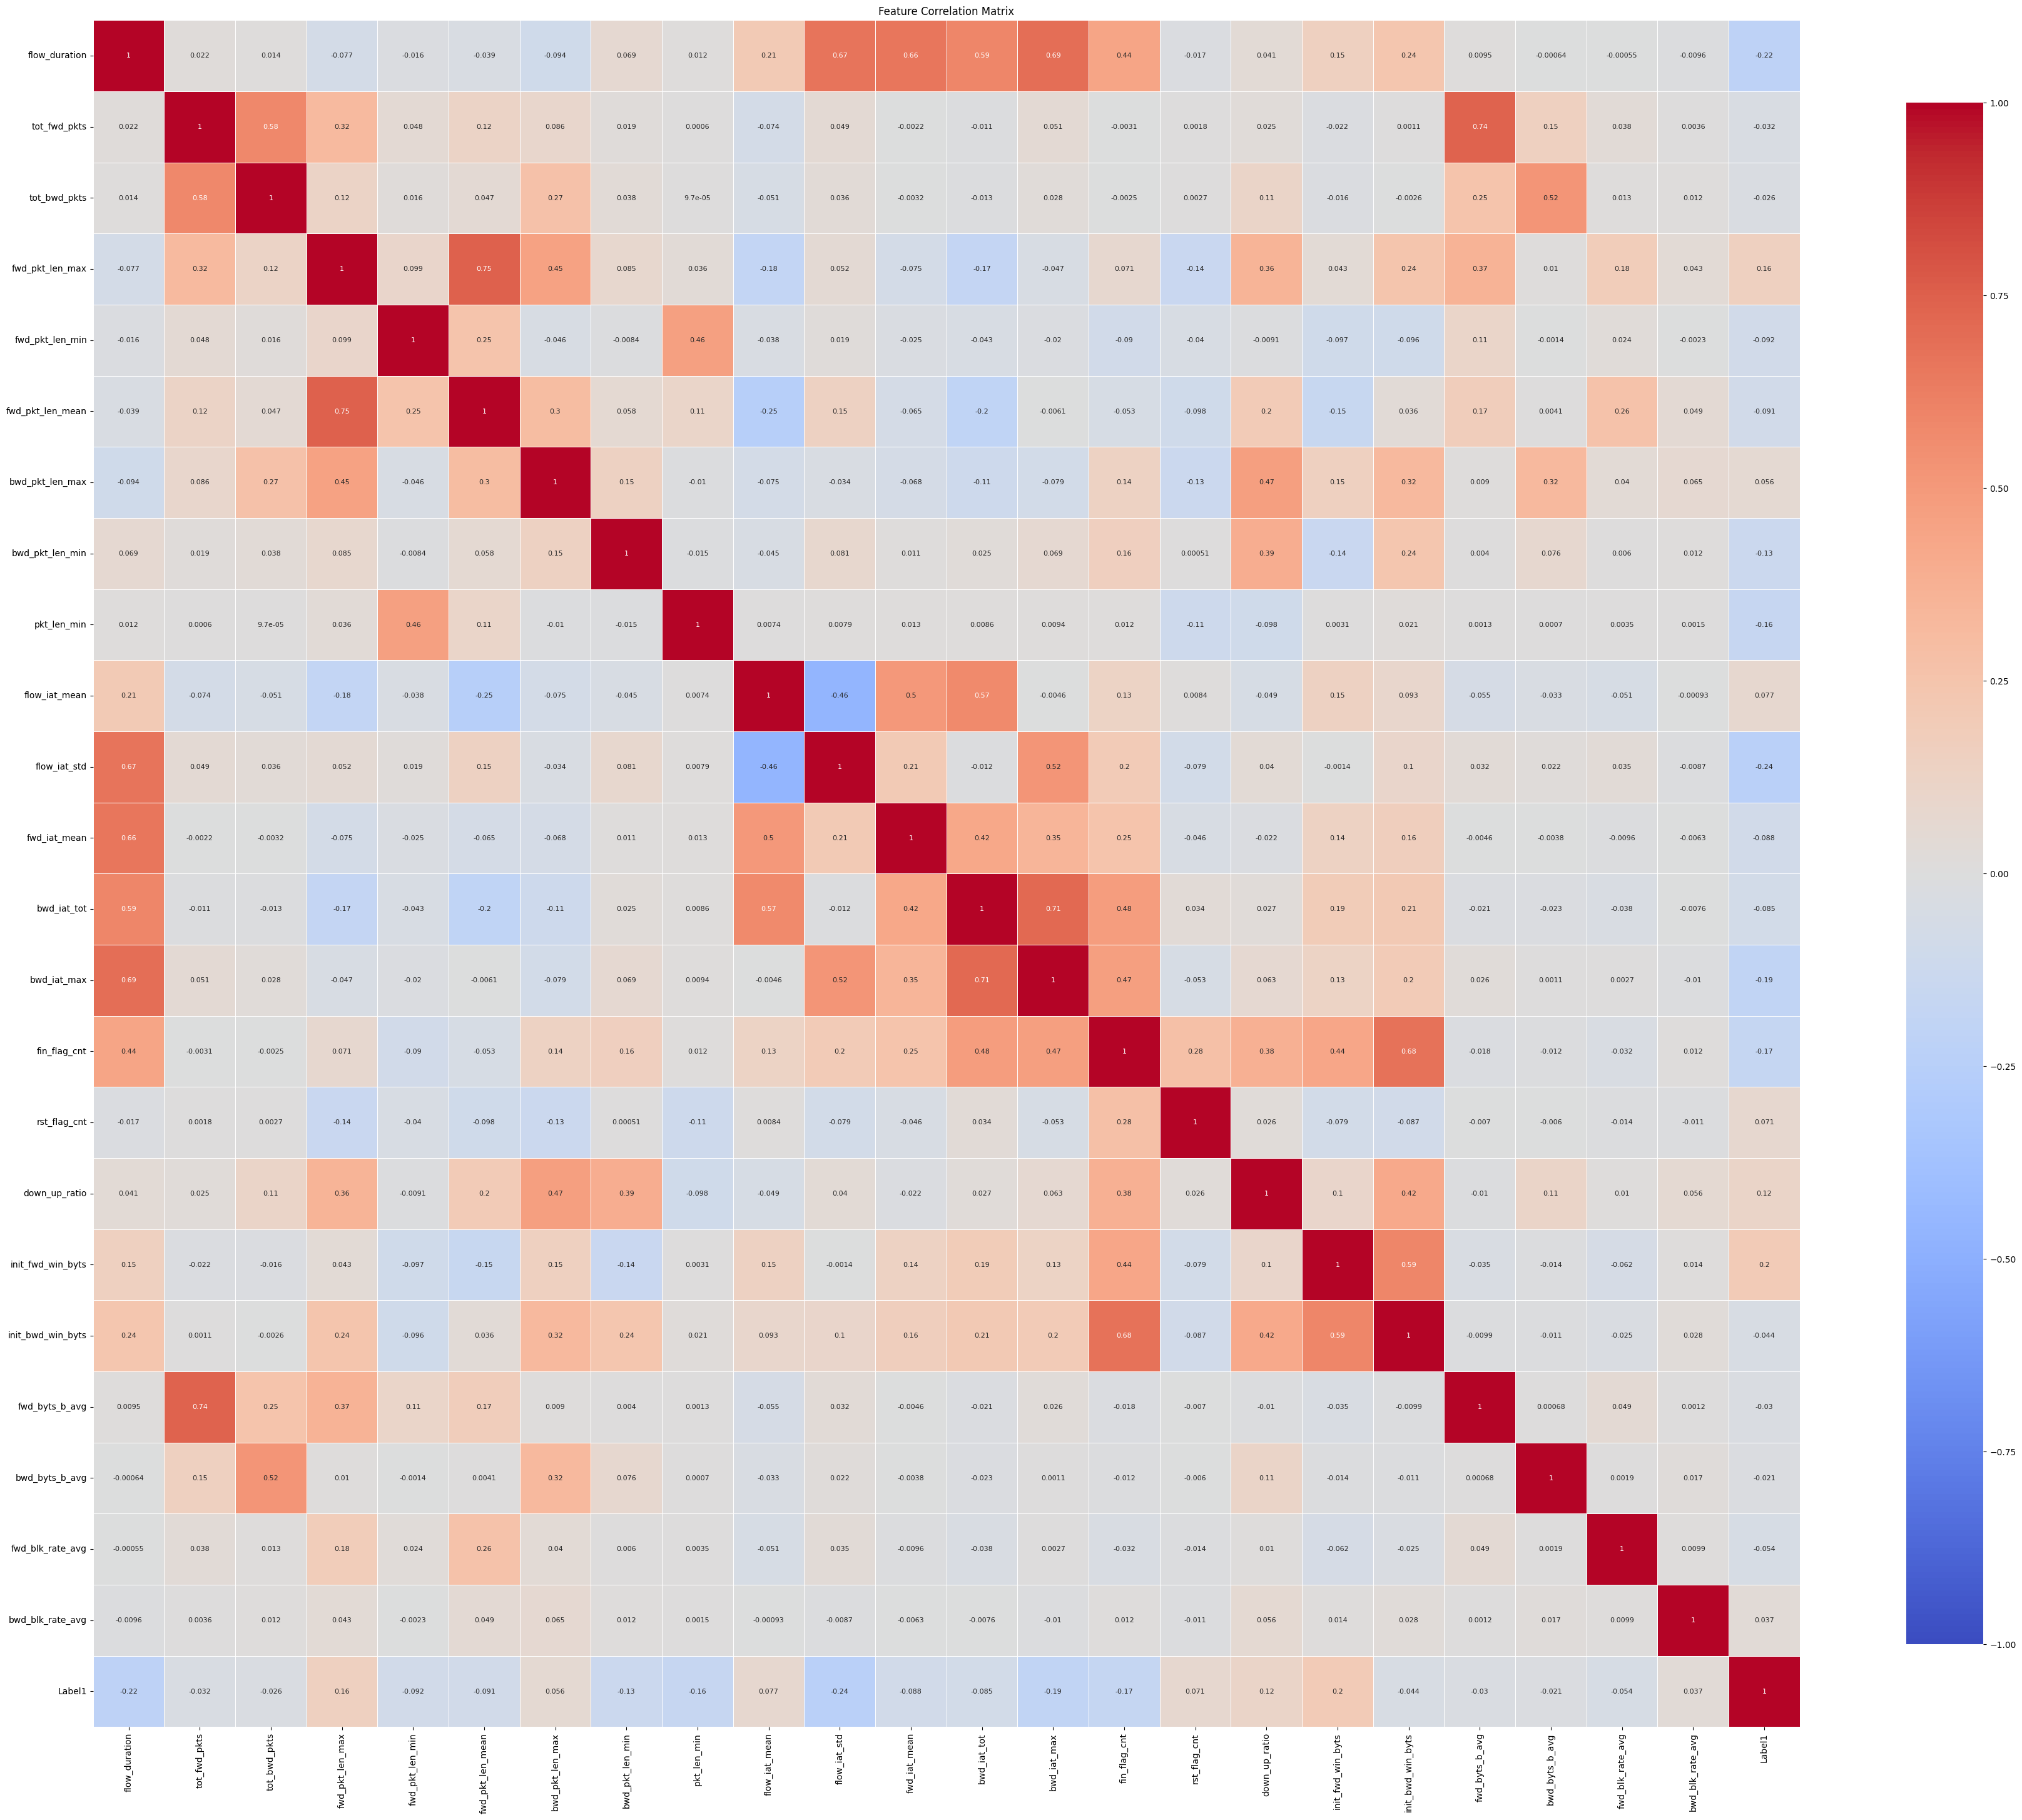

In [20]:
import seaborn as sns
numeric_df = merged_df.select_dtypes(include=[np.number])

# Drop 'Label1' if still exists
numeric_df = numeric_df.drop(columns=['Label'], errors='ignore')

# Correlation matrix
corr_matrix = numeric_df.corr()

# Heatmap (without annotation if features are many)
plt.figure(figsize=(44, 40))

sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    vmin=-1, vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    annot=True,
    annot_kws={'size': 8}  # You can increase annotation font size if you want
)

plt.title('Feature Correlation Matrix')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.show()

Feature matrix shape: (377881, 23)
Remaining samples after outlier removal: 366544

Training Random Forest...

RANDOM FOREST – TRAINING SET PERFORMANCE
              precision    recall  f1-score   support

           0       0.76      0.92      0.83     32599
           1       0.96      0.98      0.97     38104
           2       0.98      0.98      0.98     35900
           3       0.93      1.00      0.96     30425
           4       1.00      0.85      0.92     36032
           5       1.00      0.95      0.98     47265
           6       0.94      0.89      0.91     36255

    accuracy                           0.94    256580
   macro avg       0.94      0.94      0.94    256580
weighted avg       0.94      0.94      0.94    256580



<Figure size 800x600 with 0 Axes>

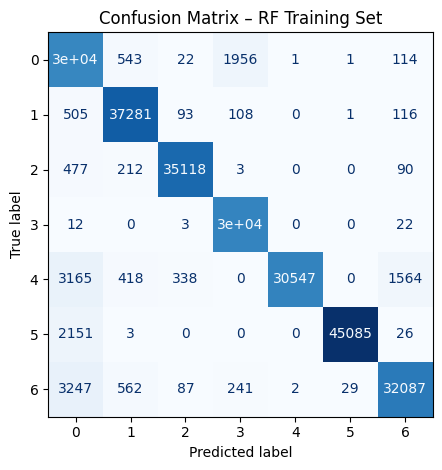


RANDOM FOREST – TEST SET PERFORMANCE
              precision    recall  f1-score   support

           0       0.75      0.92      0.83     13971
           1       0.95      0.98      0.97     16331
           2       0.98      0.98      0.98     15386
           3       0.93      1.00      0.96     13039
           4       1.00      0.85      0.92     15442
           5       1.00      0.95      0.97     20257
           6       0.94      0.88      0.91     15538

    accuracy                           0.94    109964
   macro avg       0.94      0.94      0.93    109964
weighted avg       0.94      0.94      0.94    109964



<Figure size 800x600 with 0 Axes>

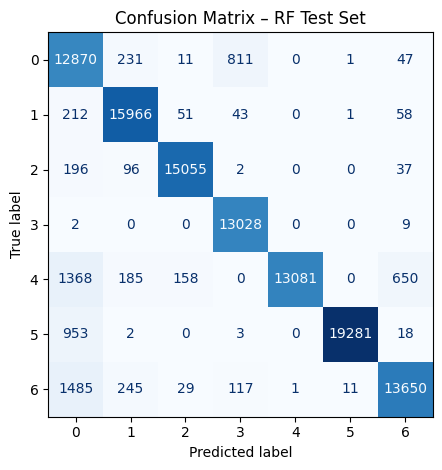


Random Forest Test Accuracy: 0.9360

Saved:
 - RF_model.pkl
 - RF_features.pkl
 - label_encoder.pkl


In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    accuracy_score
)
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import IsolationForest, RandomForestClassifier
# from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder


# =========================================================
# 1. BASIC CLEANING
# =========================================================

# Drop rows where Label is missing
merged_df = merged_df.dropna(subset=["Label1"])

# Replace infinities
merged_df = merged_df.replace([np.inf, -np.inf], np.nan)

# Encode labels safely
label_encoder = LabelEncoder()
merged_df["Label1"] = label_encoder.fit_transform(merged_df["Label1"])

# Convert all feature columns to numeric safely
X = merged_df.drop(columns=["Label1"]).apply(pd.to_numeric, errors="coerce")

# Keep only numeric columns
X = X.select_dtypes(include=[np.number])

y = merged_df["Label1"]

# Debug check
if X.shape[1] == 0:
    raise ValueError("No numeric columns found after conversion.")

print("Feature matrix shape:", X.shape)


# =========================================================
# 2. FAST OUTLIER REMOVAL
# =========================================================

imputer_temp = SimpleImputer(strategy="mean")
X_imputed = imputer_temp.fit_transform(X)

iso = IsolationForest(
    contamination=0.03,
    n_estimators=30,
    max_samples=0.7,
    random_state=34,
    n_jobs=-1
)

mask = iso.fit_predict(X_imputed) == 1

X = X.iloc[mask]
y = y.iloc[mask]

print(f"Remaining samples after outlier removal: {len(X)}")


# =========================================================
# 3. TRAIN–TEST SPLIT
# =========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    stratify=y,
    random_state=42
)


# =========================================================
# 4. RANDOM FOREST PIPELINE
# =========================================================

rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("select", SelectKBest(score_func=f_classif, k="all")),
    ("rf", RandomForestClassifier(
        max_depth=4,
        random_state=3,
        n_jobs=-1
    ))
])

print("\nTraining Random Forest...")
rf_pipeline.fit(X_train, y_train)

# =========================================================
# 5. TRAINING SET EVALUATION
# =========================================================

y_train_pred = rf_pipeline.predict(X_train)

print("\nRANDOM FOREST – TRAINING SET PERFORMANCE")
print(
    classification_report(
        y_train,
        y_train_pred,
        target_names=label_encoder.classes_.astype(str)
    )
)

plt.figure(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_train_pred,
    display_labels=label_encoder.classes_.astype(str),
    cmap="Blues",
    colorbar=False
)
plt.title("Confusion Matrix – RF Training Set")
plt.tight_layout()
plt.show()


# =========================================================
# 6. TEST SET EVALUATION
# =========================================================

y_test_pred = rf_pipeline.predict(X_test)

# Predicted probabilities
y_test_proba = rf_pipeline.predict_proba(X_test)

# Probability of class 1
y_test_proba_rf = y_test_proba[:, 1]

print("\nRANDOM FOREST – TEST SET PERFORMANCE")
print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=label_encoder.classes_.astype(str)
    )
)

plt.figure(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=label_encoder.classes_.astype(str),
    cmap="Blues",
    colorbar=False
)
plt.title("Confusion Matrix – RF Test Set")
plt.tight_layout()
plt.show()


# =========================================================
# 7. FINAL ACCURACY
# =========================================================

test_accuracy = accuracy_score(y_test, y_test_pred)
print(f"\nRandom Forest Test Accuracy: {test_accuracy:.4f}")


# =========================================================
# 8. SAVE MODEL + SELECTED FEATURES
# =========================================================

joblib.dump(rf_pipeline, "RF_model.pkl")
joblib.dump(label_encoder, "label_encoder.pkl")

# Get selected features
selector = rf_pipeline.named_steps["select"]
selected_features = X.columns
joblib.dump(selected_features.tolist(), "RF_features.pkl")

print("\nSaved:")
print(" - RF_model.pkl")
print(" - RF_features.pkl")
print(" - label_encoder.pkl")

Feature matrix shape: (377881, 23)
Remaining samples after outlier removal: 366544
Training samples: 256580
Testing samples: 109964

Training XGBoost...

XGBOOST – TRAINING SET PERFORMANCE
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     32599
           1       1.00      1.00      1.00     38104
           2       1.00      1.00      1.00     35900
           3       0.99      1.00      1.00     30425
           4       0.99      0.99      0.99     36032
           5       1.00      1.00      1.00     47265
           6       0.99      0.98      0.99     36255

    accuracy                           1.00    256580
   macro avg       1.00      1.00      1.00    256580
weighted avg       1.00      1.00      1.00    256580



<Figure size 800x600 with 0 Axes>

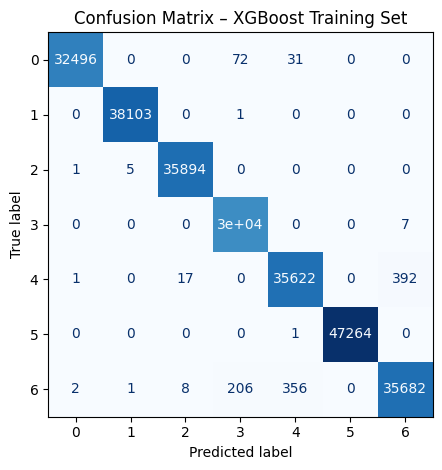


XGBOOST – TEST SET PERFORMANCE
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     13971
           1       1.00      1.00      1.00     16331
           2       1.00      1.00      1.00     15386
           3       0.99      1.00      0.99     13039
           4       0.99      0.99      0.99     15442
           5       1.00      1.00      1.00     20257
           6       0.99      0.98      0.98     15538

    accuracy                           0.99    109964
   macro avg       0.99      0.99      0.99    109964
weighted avg       0.99      0.99      0.99    109964



<Figure size 800x600 with 0 Axes>

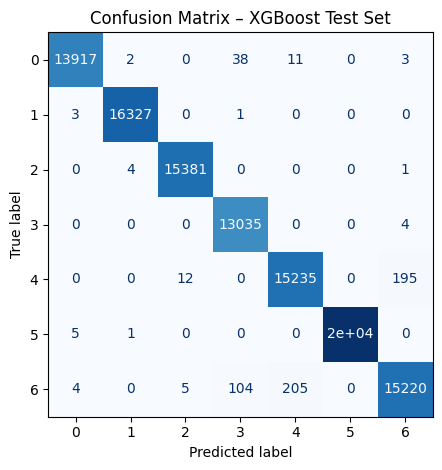


XGBoost Test Accuracy: 0.9946

Saved:
 - XGB_model.pkl
 - XGB_features.pkl
 - label_encoder.pkl


In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    accuracy_score
)
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import IsolationForest
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder

from xgboost import XGBClassifier


# =========================================================
# 1. BASIC CLEANING
# =========================================================

# Drop rows where Label is missing
merged_df = merged_df.dropna(subset=["Label1"])

# Replace infinities
merged_df = merged_df.replace([np.inf, -np.inf], np.nan)

# Encode labels safely
label_encoder = LabelEncoder()
merged_df["Label1"] = label_encoder.fit_transform(merged_df["Label1"])

# Convert all feature columns to numeric safely
X = merged_df.drop(columns=["Label1"]).apply(pd.to_numeric, errors="coerce")

# Keep only numeric columns
X = X.select_dtypes(include=[np.number])

y = merged_df["Label1"]

# Debug check
if X.shape[1] == 0:
    raise ValueError("No numeric columns found after conversion.")

print("Feature matrix shape:", X.shape)


# =========================================================
# 2. FAST OUTLIER REMOVAL
# =========================================================

imputer_temp = SimpleImputer(strategy="mean")
X_imputed = imputer_temp.fit_transform(X)

iso = IsolationForest(
    contamination=0.03,
    n_estimators=30,
    max_samples=0.7,
    random_state=34,
    n_jobs=-1
)

mask = iso.fit_predict(X_imputed) == 1

X = X.iloc[mask]
y = y.iloc[mask]

print(f"Remaining samples after outlier removal: {len(X)}")


# =========================================================
# 3. TRAIN–TEST SPLIT
# =========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    stratify=y,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


# =========================================================
# 4. XGBOOST PIPELINE
# =========================================================

xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler()),
    ("select", SelectKBest(score_func=f_classif, k="all")),
    ("xgb", XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1
    ))
])

print("\nTraining XGBoost...")
xgb_pipeline.fit(X_train, y_train)


# =========================================================
# 5. TRAINING SET EVALUATION
# =========================================================

y_train_pred = xgb_pipeline.predict(X_train)

print("\nXGBOOST – TRAINING SET PERFORMANCE")
print(
    classification_report(
        y_train,
        y_train_pred,
        target_names=label_encoder.classes_.astype(str)
    )
)

plt.figure(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_train_pred,
    display_labels=label_encoder.classes_.astype(str),
    cmap="Blues",
    colorbar=False
)
plt.title("Confusion Matrix – XGBoost Training Set")
plt.tight_layout()
plt.show()


# =========================================================
# 6. TEST SET EVALUATION
# =========================================================

y_test_pred = xgb_pipeline.predict(X_test)
y_test_proba = xgb_pipeline.predict_proba(X_test)

# Probability of class 1
y_test_proba_xgb = y_test_proba[:, 1]
print("\nXGBOOST – TEST SET PERFORMANCE")
print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=label_encoder.classes_.astype(str)
    )
)

plt.figure(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=label_encoder.classes_.astype(str),
    cmap="Blues",
    colorbar=False
)
plt.title("Confusion Matrix – XGBoost Test Set")
plt.tight_layout()
plt.show()


# =========================================================
# 7. FINAL ACCURACY
# =========================================================

test_accuracy = accuracy_score(y_test, y_test_pred)
print(f"\nXGBoost Test Accuracy: {test_accuracy:.4f}")


# =========================================================
# 8. SAVE MODEL + SELECTED FEATURES
# =========================================================

joblib.dump(xgb_pipeline, "XGB_model.pkl")
joblib.dump(label_encoder, "label_encoder.pkl")

selector = xgb_pipeline.named_steps["select"]
selected_features = X.columns

joblib.dump(selected_features.tolist(), "XGB_features.pkl")
scaler = xgb_pipeline.named_steps["scaler"]
joblib.dump(scaler, "scaler.pkl")
print("\nSaved:")
print(" - XGB_model.pkl")
print(" - XGB_features.pkl")
print(" - label_encoder.pkl")

Feature matrix shape: (377881, 23)
Remaining samples after outlier removal: 366544
Training samples: 256580
Testing samples: 109964

Training KNN...

KNN – TRAINING SET PERFORMANCE
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     32599
           1       1.00      1.00      1.00     38104
           2       1.00      1.00      1.00     35900
           3       1.00      1.00      1.00     30425
           4       1.00      1.00      1.00     36032
           5       1.00      1.00      1.00     47265
           6       1.00      1.00      1.00     36255

    accuracy                           1.00    256580
   macro avg       1.00      1.00      1.00    256580
weighted avg       1.00      1.00      1.00    256580



<Figure size 800x600 with 0 Axes>

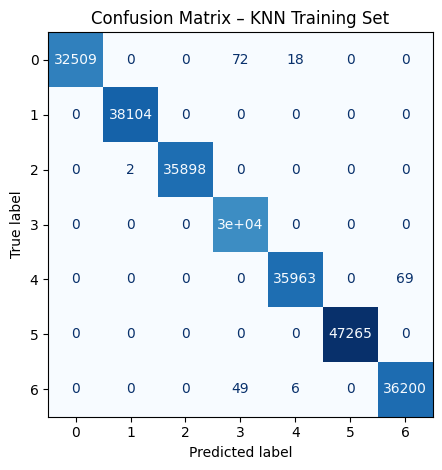


KNN – TEST SET PERFORMANCE
              precision    recall  f1-score   support

           0       1.00      0.99      1.00     13971
           1       1.00      1.00      1.00     16331
           2       1.00      1.00      1.00     15386
           3       0.99      1.00      0.99     13039
           4       0.99      0.98      0.98     15442
           5       1.00      1.00      1.00     20257
           6       0.98      0.98      0.98     15538

    accuracy                           0.99    109964
   macro avg       0.99      0.99      0.99    109964
weighted avg       0.99      0.99      0.99    109964



<Figure size 800x600 with 0 Axes>

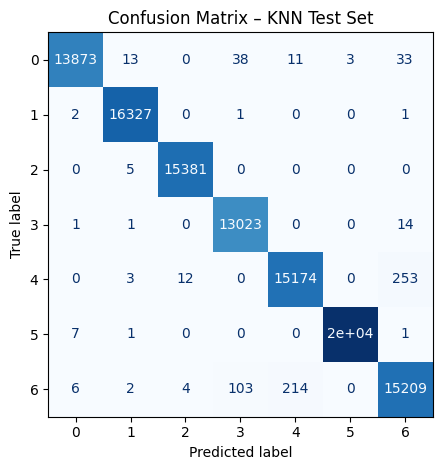

Saved Knn_Prob_Class1.csv

KNN Test Accuracy: 0.9934

Saved:
 - KNN_model.pkl
 - KNN_features.pkl
 - label_encoder.pkl


In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    accuracy_score
)
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import IsolationForest
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# 1. BASIC CLEANING

# Drop rows where Label is missing
merged_df = merged_df.dropna(subset=["Label1"])

# Replace infinities
merged_df = merged_df.replace([np.inf, -np.inf], np.nan)

# Encode labels
label_encoder = LabelEncoder()
merged_df["Label1"] = label_encoder.fit_transform(merged_df["Label1"])

# Convert features to numeric
X = merged_df.drop(columns=["Label1"]).apply(pd.to_numeric, errors="coerce")

# Keep numeric columns only
X = X.select_dtypes(include=[np.number])

y = merged_df["Label1"]

if X.shape[1] == 0:
    raise ValueError("No numeric columns found.")

print("Feature matrix shape:", X.shape)


# =========================================================
# 2. FAST OUTLIER REMOVAL
# =========================================================

imputer_temp = SimpleImputer(strategy="mean")
X_imputed = imputer_temp.fit_transform(X)

iso = IsolationForest(
    contamination=0.03,
    n_estimators=30,
    max_samples=0.7,
    random_state=34,
    n_jobs=-1
)

mask = iso.fit_predict(X_imputed) == 1

X = X.iloc[mask]
y = y.iloc[mask]

print(f"Remaining samples after outlier removal: {len(X)}")


# =========================================================
# 3. TRAIN–TEST SPLIT
# =========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    stratify=y,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


# =========================================================
# 4. KNN PIPELINE
# =========================================================

knn_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler()),     # important for KNN
    ("select", SelectKBest(score_func=f_classif, k="all")),
    ("knn", KNeighborsClassifier(
        n_neighbors=5,
        weights="distance",
        n_jobs=-1
    ))
])

print("\nTraining KNN...")
knn_pipeline.fit(X_train, y_train)


# =========================================================
# 5. TRAINING SET EVALUATION
# =========================================================

y_train_pred = knn_pipeline.predict(X_train)

print("\nKNN – TRAINING SET PERFORMANCE")
print(
    classification_report(
        y_train,
        y_train_pred,
        target_names=label_encoder.classes_.astype(str)
    )
)

plt.figure(figsize=(8,6))
ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_train_pred,
    display_labels=label_encoder.classes_.astype(str),
    cmap="Blues",
    colorbar=False
)
plt.title("Confusion Matrix – KNN Training Set")
plt.tight_layout()
plt.show()


# =========================================================
# 6. TEST SET EVALUATION
# =========================================================

y_test_pred = knn_pipeline.predict(X_test)

# Class 1 probability
y_test_proba_knn = (
    knn_pipeline.predict_proba(X_test)[:,1]
)
print("\nKNN – TEST SET PERFORMANCE")
print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=label_encoder.classes_.astype(str)
    )
)

plt.figure(figsize=(8,6))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=label_encoder.classes_.astype(str),
    cmap="Blues",
    colorbar=False
)
plt.title("Confusion Matrix – KNN Test Set")
plt.tight_layout()
plt.show()

knn_prob_df = pd.DataFrame({
    "Actual_Label": y_test.values,
    "Predicted_Label": y_test_pred,
    "SVM_Prob_Class1": y_test_proba_knn
})

knn_prob_df.to_csv(
    "Knn_Prob_Class1.csv",
    index=False
)

print("Saved Knn_Prob_Class1.csv")


# =========================================================
# 7. FINAL ACCURACY
# =========================================================

test_accuracy = accuracy_score(y_test, y_test_pred)
print(f"\nKNN Test Accuracy: {test_accuracy:.4f}")


# =========================================================
# 8. SAVE MODEL + FEATURES
# =========================================================

joblib.dump(knn_pipeline, "KNN_model.pkl")
joblib.dump(label_encoder, "label_encoder.pkl")

selector = knn_pipeline.named_steps["select"]
selected_features = X.columns

joblib.dump(selected_features.tolist(), "KNN_features.pkl")

print("\nSaved:")
print(" - KNN_model.pkl")
print(" - KNN_features.pkl")
print(" - label_encoder.pkl")

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    accuracy_score
)
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import IsolationForest
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV


# =========================================================
# 1. BASIC CLEANING
# =========================================================
print(merged_df.shape)
# Drop rows where Label is missing
merged_df = merged_df.dropna(subset=["Label1"])

# Replace infinities
merged_df = merged_df.replace([np.inf, -np.inf], np.nan)

# Encode labels safely
label_encoder = LabelEncoder()
merged_df["Label1"] = label_encoder.fit_transform(merged_df["Label1"])

# Convert all feature columns to numeric safely
X = merged_df.drop(columns=["Label1"]).apply(pd.to_numeric, errors="coerce")

# Keep only numeric columns
X = X.select_dtypes(include=[np.number])

y = merged_df["Label1"]

# Debug check
if X.shape[1] == 0:
    raise ValueError("No numeric columns found after conversion.")

print("Feature matrix shape:", X.shape)


# =========================================================
# 2. FAST OUTLIER REMOVAL
# =========================================================

imputer_temp = SimpleImputer(strategy="mean")
X_imputed = imputer_temp.fit_transform(X)

iso = IsolationForest(
    contamination=0.03,
    n_estimators=30,
    max_samples=0.7,
    random_state=34,
    n_jobs=-1
)

mask = iso.fit_predict(X_imputed) == 1

X = X.iloc[mask]
y = y.iloc[mask]

print(f"Remaining samples after outlier removal: {len(X)}")


# =========================================================
# 3. TRAIN–TEST SPLIT
# =========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    stratify=y,
    random_state=42
)


# =========================================================
# 4. SVM PIPELINE
# =========================================================

svm_pipeline = Pipeline([

    # SAME imputation
    (
        "imputer",
        SimpleImputer(
            strategy="mean"
        )
    ),


    # Required for SVM
    (
        "scaler",
        StandardScaler()
    ),


    # SAME feature selection
    (
        "select",
        SelectKBest(
            score_func=f_classif,
            k="all"
        )
    ),


    # SVM with probability
    (
        "svm",
        CalibratedClassifierCV(
            LinearSVC(
                C=1.0,
                max_iter=5000,
                random_state=42
            ),
            cv=3
        )
    )

])


print("\nTraining SVM...")

svm_pipeline.fit(
    X_train,
    y_train
)



# =========================================================
# 5. TRAINING PERFORMANCE
# =========================================================

y_train_pred = svm_pipeline.predict(
    X_train
)


print("\nSVM TRAINING PERFORMANCE")

print(
    classification_report(
        y_train,
        y_train_pred,
        target_names=label_encoder.classes_.astype(str)
    )
)



# =========================================================
# 6. TEST PERFORMANCE + PROBABILITY
# =========================================================

y_test_pred = svm_pipeline.predict(
    X_test
)


# Class 1 probability
y_test_proba_svm = (
    svm_pipeline
    .predict_proba(X_test)[:,1]
)


print("\nFirst 10 SVM Class-1 probabilities:")
print(y_test_proba_svm[:10])


print("\nSVM TEST PERFORMANCE")

print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=label_encoder.classes_.astype(str)
    )
)



# =========================================================
# 7. ACCURACY
# =========================================================

accuracy = accuracy_score(
    y_test,
    y_test_pred
)


print(
    "\nSVM Test Accuracy:",
    round(accuracy,4)
)



# =========================================================
# 8. SAVE PROBABILITY CSV
# =========================================================
svm_prob_df = pd.DataFrame({
    "Actual_Label": y_test.values,
    "Predicted_Label": y_test_pred,
    "SVM_Prob_Class1": y_test_proba_svm
})

svm_prob_df.to_csv(
    "SVM_Prob_Class1.csv",
    index=False
)

print("Saved SVM_Prob_Class1.csv")


# =========================================================
# 9. SAVE MODEL
# =========================================================

joblib.dump(
    svm_pipeline,
    "SVM_model.pkl"
)


joblib.dump(
    label_encoder,
    "label_encoder.pkl"
)


joblib.dump(
    X.columns.tolist(),
    "SVM_features.pkl"
)


print("\nSaved:")
print("SVM_model.pkl")
print("SVM_features.pkl")
print("label_encoder.pkl")

(377881, 24)
Feature matrix shape: (377881, 23)
Remaining samples after outlier removal: 366544

Training SVM...

SVM TRAINING PERFORMANCE
              precision    recall  f1-score   support

           0       0.77      0.85      0.80     32599
           1       0.90      0.97      0.93     38104
           2       0.99      0.99      0.99     35900
           3       0.95      1.00      0.97     30425
           4       0.93      0.88      0.90     36032
           5       1.00      0.95      0.98     47265
           6       0.91      0.83      0.87     36255

    accuracy                           0.92    256580
   macro avg       0.92      0.92      0.92    256580
weighted avg       0.93      0.92      0.92    256580


First 10 SVM Class-1 probabilities:
[5.72037207e-02 2.60441158e-06 2.03242516e-03 3.57197986e-06
 8.33824390e-14 8.66920959e-01 2.03242508e-03 2.29819865e-01
 1.43054170e-06 1.69263161e-01]

SVM TEST PERFORMANCE
              precision    recall  f1-score   suppo

In [25]:
# prob_df = pd.DataFrame()

# prob_df["RF_ProbClass1"] = y_test_proba_rf
# prob_df["KNN_ProbClass1"] = y_test_proba_knn
# prob_df["XGB_ProbClass1"] = y_test_proba_xgb
# prob_df["SVM_ProbClass1"] = y_test_proba_svm

# # Save
# prob_df.to_csv(
#     "All_Model_Probability.csv",
#     index=False
# )
# print("Saved All_Model_Probabilities.csv")

In [26]:
overall = (
    y_test_proba_rf +
    y_test_proba_knn +
    y_test_proba_xgb +
    y_test_proba_svm
) / 4

threshold = 0.70

prediction = np.where(overall > threshold, 1, 0)


In [27]:
# from sklearn.ensemble import VotingClassifier
# from sklearn.pipeline import Pipeline
# from sklearn.impute import SimpleImputer
# from sklearn.feature_selection import SelectKBest, f_classif
# from sklearn.preprocessing import StandardScaler
# from sklearn.metrics import classification_report, accuracy_score
# import joblib

# # --- Hybrid Pipeline ---
# hybrid_pipeline = Pipeline([
#     ("imputer", SimpleImputer(strategy="mean")),
#     ("select", SelectKBest(score_func=f_classif)),
#     ("scaler", StandardScaler()),  # needed for KNN & MLP
    
#     ("ensemble", VotingClassifier(
#         estimators=[
#             ("knn", knn_pipeline),
#             ("xgboost", xgb_pipeline),
#             ("rf", rf_pipeline)
#         ],
#         voting="hard",
#         weights=[3, 7, 5],   # one weight per model
#         n_jobs=-1
#     ))
# ])

# print("\nRunning HYBRID Ensemble...")
# hybrid_pipeline.fit(X_train, y_train)

# # =========================================================
# # TEST EVALUATION
# # =========================================================

# y_test_pred_hybrid = hybrid_pipeline.predict(X_test)

# print("\nHYBRID MODEL – TEST SET PERFORMANCE")

# print(classification_report(
#     y_test,
#     y_test_pred_hybrid,
#     target_names=label_encoder.classes_.astype(str)
# ))

# print("Hybrid Accuracy:",
#       accuracy_score(y_test, y_test_pred_hybrid))

# # =========================================================
# # SAVE HYBRID MODEL
# # =========================================================

# joblib.dump(hybrid_pipeline, "AD_Hybrid_model.pkl")

# print("Saved Hybrid_model.pkl")